### **1. 1D Steady-State Heat Equation**

Consider the one-dimensional steady-state heat conduction problem with a heat source on a rod of unit length. The governing equation is:
$$
\frac{d^{2}T}{dx^{2}}+\frac{q(x)}{k}=0, x\in[0,1]
$$
with homogeneous Dirichlet boundary conditions:
$$
T(0)=T(1)=0.
$$
Given a thermal diffusivity constant: $κ = 0.5$ and Heat source term: $q(x) = 15x − 2$.

a) Design a physics-informed neural network with:

    • Input dimension: 1 (spatial coordinate x)
    • Three hidden layers with 32 neurons each
    • Hyperbolic tangent activation functions
    • Output dimension: 1 (temperature T)
    
b) Construct the physics-informed loss function $L_{Physics}$ that enforces the PDE.

c) Write the boundary loss function $L_{BCs}$.

d) Train the network using:

- $N_f$ = 100 equidistant collocation points
- Total loss $L = L_{BCs} + L_{Physics}$
- Adam optimizer with learning rate $10^{−3}$
- 10,000 epochs
    
e) Derive the analytical solution and compare it with the numerical solution. Plot both solutions and compute the relative $L^{2}$ error.

## **Answer**
**a)** Design a PINN 

In [29]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

class MLP(torch.nn.Module):
    def __init__(self, hidden_size=32, hidden_layer=3):
        super(MLP, self).__init__()
        layer = [torch.nn.Linear(1, hidden_size), torch.nn.Tanh()]
        for _ in range(hidden_layer-1):
            layer.append(torch.nn.Linear(hidden_size, hidden_size))
            layer.append(torch.nn.Tanh())
        layer.append(torch.nn.Linear(hidden_size, 1))
        self.model = torch.nn.Sequential(*layer)

    def forward(self, x):
        return self.model(x)

**b)** Construct the physics-informed loss function 

In [30]:
def physics_loss(model, x_colloc, k=0.5):
    x_colloc = x_colloc.clone().requires_grad_(True)
    t = model(x_colloc)

    dT_dx = torch.autograd.grad(
        outputs = t,
        inputs = x_colloc,
        grad_outputs = torch.ones_like(t),
        create_graph = True,
    )[0]
    
    d2T_dx2 = torch.autograd.grad(
        outputs = dT_dx,
        inputs = x_colloc,
        grad_outputs = torch.ones_like(dT_dx),
        create_graph = True,
        retain_graph = True
    )[0]

    residuals = d2T_dx2 + (15*x_colloc - 2)/k
    physic_loss = torch.mean(residuals**2)
    return physic_loss

**c)** Write the boundary loss function

In [31]:
def boundary_loss(model, x_boundary):
    t_boundary = model(x_boundary)
    return torch.mean(t_boundary**2)

**d)** Train the network

In [38]:
def train_pinn(model, epochs = 4000, learning_rate = 0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    x_train = np.linspace(0, 1, 100).reshape(-1, 1)
    x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
    x_boundary = torch.tensor([[0.0], [1.0]], dtype=torch.float32)

    losses = {'total':[], 'pde':[], 'boundary':[]}

    for _ in range(epochs):
        optimizer.zero_grad()
    
        L_physic = physics_loss(model, x_train_tensor)
        L_boundary = boundary_loss(model, x_boundary)
        L_total = L_physic + L_boundary

        L_total.backward()
        optimizer.step()
        losses['total'].append(L_total.item())
        losses['pde'].append(L_physic.item())
        losses['boundary'].append(L_boundary.item())
        if _%2000 == 0:
            print(f'training epoch {_}/{epochs}: total loss is {L_total.item():.4e}, pde loss is {L_physic.item():.4e} and boundary loss is {L_boundary.item():.4e}')
    return model, losses

model = MLP()
trained_model, losses = train_pinn(model)

training epoch 0/4000: total loss is 1.9638e+02, pde loss is 1.9638e+02 and boundary loss is 1.6097e-03
training epoch 2000/4000: total loss is 6.2796e-04, pde loss is 6.0441e-04 and boundary loss is 2.3553e-05


**e)** Compare the solution with analytical solution

The analytical solution is: $T(x)=-5 x^{3}+2 x^{2}+3x$

The L2 error between analytical and pinn solution is: 0.0003, and the relative L2 error is: 2.4945e-07


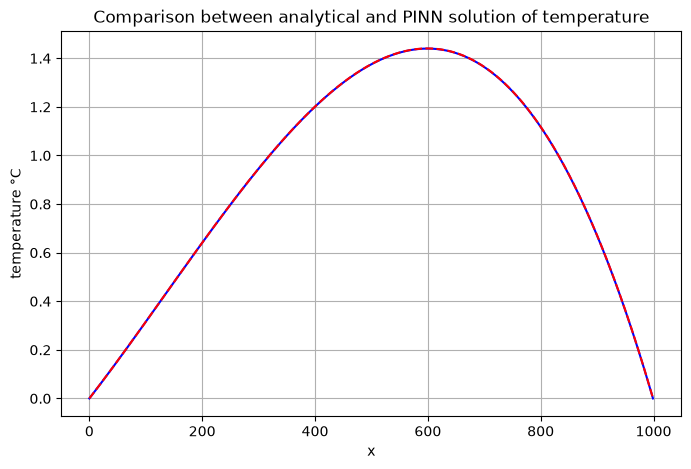

In [39]:
x_test = np.linspace(0, 1, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype=torch.float32)
y = lambda x: -5*x**3+2*x**2+3*x
T_analytical = y(x_test)
T_pinn = trained_model.forward(x_test_tensor).detach().numpy()

fig, ax = plt.subplots(1,1, figsize=(8,5))
ax.plot(T_analytical, 'blue', label='analytical solution of temperature')
ax.plot(T_pinn, 'red', linestyle='--', label='pinn solution of temperature')
ax.grid(True)
ax.set_xlabel('x')
ax.set_ylabel('temperature °C')
ax.set_title('Comparison between analytical and PINN solution of temperature')
print(f'The L2 error between analytical and pinn solution is: {np.sum((T_analytical.reshape(-1,1) - T_pinn)**2):.4f}, and the relative L2 error is: {np.sum((T_analytical.reshape(-1,1) - T_pinn)**2)/np.sum(T_analytical**2):.4e}')

### **2. Loss Function Design**

Investigate different formulations of the loss function:

**a)** Implement adaptive loss weighting:
$$
L = α(t)L_{BCs} + β(t)L_{Physics}
$$

where $α(t)$ and $β(t)$ are dynamic weights. Compare with the original fixed-weight formulation.

### **Answer**
**a)**

After implementing the adaptive loss weights, the L2 error between analytical and PINN solution increased a bit from 0.0003 to 0.0026, which is negligible. Both have a good prediction.

The lambda for pde loss and boundary loss are initialized with -4.6, so the weights for both losses are initialized with 1.

During the training, at 2000 iterations, lambda for pde loss increased to 7.21, while the lambda for boundary loss increased to 5.23. Because the pde loss was higher than the boundary loss, the weight for pde loss then increased faster than the weight for boundary loss.

In [40]:
def train_pinn_with_weights(model, epochs = 4000, learning_rate = 0.001):
    lambda_pde = torch.nn.Parameter(torch.tensor(-4.6), requires_grad=True)
    lambda_bc = torch.nn.Parameter(torch.tensor(-4.6), requires_grad=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    lambda_optimizer = torch.optim.SGD([lambda_pde, lambda_bc], lr=learning_rate, maximize=True)

    x_train = np.linspace(0, 1, 100).reshape(-1, 1)
    x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
    x_boundary = torch.tensor([[0.0], [1.0]], dtype=torch.float32)

    losses = {'total':[], 'pde':[], 'boundary':[]}
    lambda_pde_values = []
    lambda_bc_values = []

    for _ in range(epochs):
        optimizer.zero_grad()
        lambda_optimizer.zero_grad()
    
        L_physic = physics_loss(model, x_train_tensor)
        L_boundary = boundary_loss(model, x_boundary)

        w_pde = 100*torch.sigmoid(lambda_pde)
        w_bc = 100*torch.sigmoid(lambda_bc)
        
        L_total = w_pde*L_physic + w_bc*L_boundary

        L_total.backward()
        optimizer.step()
        lambda_optimizer.step()
        
        losses['total'].append(L_total.item())
        losses['pde'].append(L_physic.item())
        losses['boundary'].append(L_boundary.item())

        lambda_pde_values.append(w_pde.item())
        lambda_bc_values.append(w_bc.item())
        if _%2000 == 0:
            print(f'training epoch {_}/{epochs}: total loss is {L_total.item():.4e}, pde loss is {L_physic.item():.4e}, boundary loss is {L_boundary.item():.4e},' 
                  f'lambda_pde is: {lambda_pde.item():.2f} and lambda_bc is {lambda_bc.item():.2f}')
    return model, losses, lambda_pde_values, lambda_bc_values

model = MLP()
trained_model, losses, lambda_pde_values, lambda_bc_values = train_pinn_with_weights(model)

training epoch 0/4000: total loss is 1.9832e+02, pde loss is 1.9927e+02, boundary loss is 9.6563e-03,lambda_pde is: -4.40 and lambda_bc is -4.60
training epoch 2000/4000: total loss is 5.1474e-01, pde loss is 5.1327e-03, boundary loss is 1.8525e-05,lambda_pde is: 7.21 and lambda_bc is 5.23


The L2 error between analytical and pinn solution is: 0.0026, and the relative L2 error is: 2.5375e-06


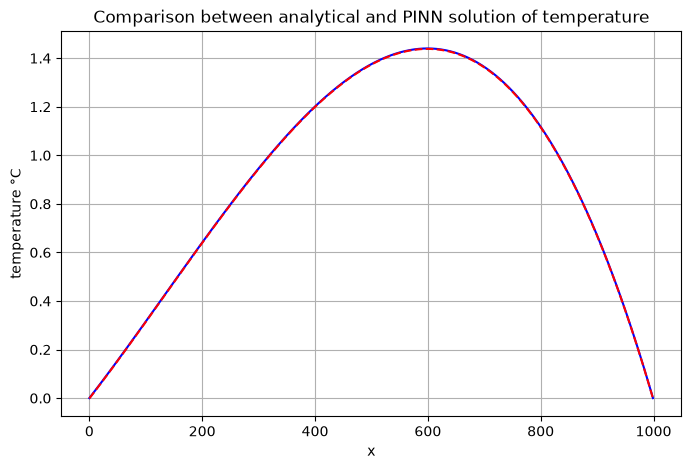

In [41]:
x_test = np.linspace(0, 1, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype=torch.float32)
y = lambda x: -5*x**3+2*x**2+3*x
T_analytical = y(x_test)
T_pinn_adv_w = trained_model.forward(x_test_tensor).detach().numpy()

fig, ax = plt.subplots(1,1, figsize=(8,5))
ax.plot(T_analytical, 'blue', label='analytical solution of temperature')
ax.plot(T_pinn_adv_w, 'red', linestyle='--', label='pinn solution of temperature')
ax.grid(True)
ax.set_xlabel('x')
ax.set_ylabel('temperature °C')
ax.set_title('Comparison between analytical and PINN solution of temperature')
print(f'The L2 error between analytical and pinn solution is: {np.sum((T_analytical.reshape(-1,1) - T_pinn_adv_w)**2):.4f}, and the relative L2 error is: {np.sum((T_analytical.reshape(-1,1) - T_pinn_adv_w)**2)/np.sum(T_analytical**2):.4e}')

### **3. Variational Formulation**

Implement and analyze a variational (weak) form of the problem:

a) Derive the weak form by multiplying the PDE by test functions $ϕ(x)$ and integrating:
$$
\int_{0}^{1}\frac{dT}{dx}\frac{d\phi}{dx}dx=\int_{0}^{1}\frac{q(x)}{k}\phi dx
$$

b) Implement this formulation using neural networks and compare with the strong form implementation

### **Answer**

**a)**

The governing equation is:
$$
\frac{d^{2}T}{dx^{2}}+\frac{q(x)}{k}=0
$$
multiplying the equation by the test function $\phi(x)$:
$$
\frac{d^{2}T}{dx^{2}}\cdot \phi (x)+\frac{q(x)}{k}\cdot \phi (x)=0
$$
an integrating:
$$
\int_0^{1}\frac{d^{2}T}{dx^{2}}\cdot \phi (x)dx+\int_0^{1}\frac{q(x)}{k}\cdot \phi (x)dx=0
$$
$$
\int_0^{1}(\frac{dT}{dx}\cdot \phi (x)-\frac{dT}{dx}\cdot \frac{d\phi (x)}{dx}) dx+\int_0^{1}\frac{q(x)}{k}\cdot \phi (x)dx =0
$$
$$
\int_0^{1}\frac{dT}{dx}\cdot \frac{d\phi (x)}{dx}dx-[T(x)\cdot \phi (x)]_0^{1}=\int_0^{1}\frac{q(x)}{k}\cdot \phi (x)dx
$$

because $T(0)=T(1)=0$,
$$
\int_0^{1}\frac{dT}{dx}\cdot \frac{d\phi (x)}{dx}dx = \int_0^{1}\frac{q(x)}{k}\cdot \phi (x)dx
$$

**b)**

In [42]:
def loss_with_weak_form(model, x_colloc, k=10):
    x_colloc = x_colloc.clone().requires_grad_(True)
    t = model(x_colloc)

    loss = 0

    dt_dx = torch.autograd.grad(t, x_colloc, torch.ones_like(t), create_graph=True)[0]
    for i in range(k):
        i += 1
        dphi_dx = i*np.pi*torch.cos(i*np.pi*x_colloc)
        phi = torch.sin(i*np.pi*x_colloc)
        lhs = torch.trapz((dt_dx * dphi_dx).squeeze(), x_colloc.squeeze())
        rhs = torch.trapz((15*x_colloc-2).squeeze()/0.5*phi.squeeze(), x_colloc.squeeze())
        loss += (lhs - rhs) ** 2
    return loss

def train_MLP_with_weak_form(model, x_train, epochs=4000, learning_rate=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    x_boundary = torch.tensor([[0.0], [1.0]], dtype=torch.float32)
    losses = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss_boundary = boundary_loss(model, x_boundary)
        loss = loss_with_weak_form(model, x_train) + loss_boundary
            
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if _ % 2000 == 0:
            print(f'training {_}/{epochs}epochs: the loss is {loss.item():.4e}')
    return model, losses

x_train = np.linspace(0,1,300)
x_train_tensor = torch.tensor(x_train.reshape(-1,1), dtype=torch.float32)
model = MLP()
trained_model, losses = train_MLP_with_weak_form(model, x_train_tensor)

training 0/4000epochs: the loss is 9.1614e+01
training 2000/4000epochs: the loss is 3.0020e-03


The L2 error between analytical and pinn solution is: 0.0054, and the relative L2 error is: 5.2023e-06


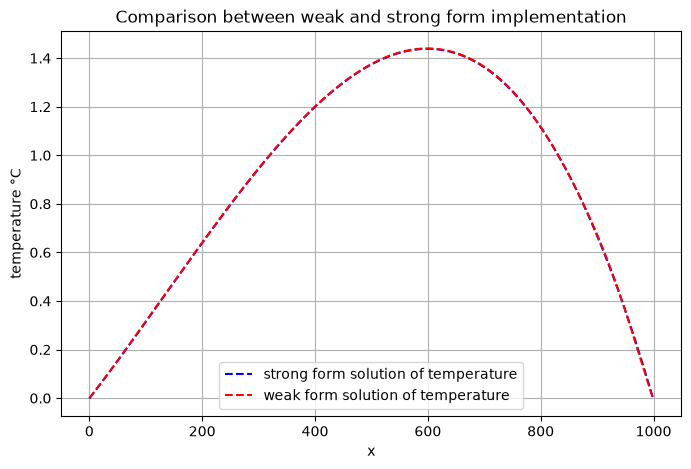

In [43]:
x_test = np.linspace(0, 1, 1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype=torch.float32)
y = lambda x: -5*x**3+2*x**2+3*x
T_analytical = y(x_test)
T_pinn_weak_form = trained_model.forward(x_test_tensor).detach().numpy()

fig, ax = plt.subplots(1,1, figsize=(8,5))
#ax.plot(T_analytical, 'blue', label='analytical solution of temperature')
ax.plot(T_pinn_adv_w, 'blue', linestyle='--', label='strong form solution of temperature')
ax.plot(T_pinn_weak_form, 'red', linestyle='--', label='weak form solution of temperature')
ax.grid(True)
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('temperature °C')
ax.set_title('Comparison between weak and strong form implementation')
print(f'The L2 error between analytical and pinn solution is: {np.sum((T_pinn_adv_w.reshape(-1,1) - T_pinn_weak_form)**2):.4f}, and the relative L2 error is: {np.sum((T_pinn_weak_form.reshape(-1,1) - T_pinn_adv_w)**2)/np.sum(T_pinn_adv_w**2):.4e}')

### **4. Data-Driven Cross-Section Identification**

Consider the static bar equation where the displacement field u(x) is known but the cross-sectional properties $EA(x)$ need to be identified:
$$
\frac{d}{dx}(EA(x)\frac{du}{dx})+p(x)=0, \space x \in[0,1]
$$

Given:
- Displacement field: $u(x) = sin(2πx)$
- Distributed load: $p(x) = −2(3x^{2} − 2x)π cos(2πx) + 4(x^{3} − x^{2} + 1)π^{2} sin(2πx)$
- Domain: $x \in [0, 1]$
- Boundary conditions: $u(0) = u(1) = 0$

**a)** Design a physics-informed neural network to identify $EA(x)$ with:
- Input dimensions: 2 (spatial coordinate $x$ and displacement $u$)
- Three hidden layers with 20 neurons each
- Hyperbolic tangent activation functions
- Output dimension: 1 (stiffness $EA$)

In [81]:
class PINN_tanh(torch.nn.Module):
    def __init__(self, hidden_layers=20, nlayers=3):
        super(PINN_tanh, self).__init__()
        self.activation = torch.nn.Tanh()
        layers = [torch.nn.Linear(2, hidden_layers), self.activation]
        for _ in range(nlayers-1):
            layers.append(torch.nn.Linear(hidden_layers, hidden_layers))
            layers.append(self.activation)
        layers.append(torch.nn.Linear(hidden_layers, 1))
        self.model = torch.nn.Sequential(*layers)
        
    def forward(self,x,u):
        return self.model(torch.cat([x,u], dim=1))

**b)** Formulate the physics-informed loss function that enforces the differential equation.

In [86]:
def physics_loss(model, x):
    x = x.clone().requires_grad_(True)
    u = torch.sin(2*np.pi*x)
    
    EA = model(x,u)
    p = -2*(3*x**2-2*x)*np.pi*torch.cos(2*np.pi*x) + 4*(x**3-x**2+1)*np.pi**2*torch.sin(2*np.pi*x)
    du_dx = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    dEA_du_dx_dx = torch.autograd.grad(EA*du_dx, x, torch.ones_like(EA*du_dx), create_graph=True)[0]

    loss = torch.mean((dEA_du_dx_dx+p)**2)
    return loss

**c)** Train the network using:
- $N = 100$ uniformly distributed training points
- Adam optimizer with learning rate $10^{−3}$
- 5,000 epochs

In [89]:
def training_model(model, epochs=5000, learning_rate=0.001):
    x_train = torch.tensor(np.linspace(0,1,100).reshape(-1,1), dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
    losses = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = physics_loss(model, x_train)
        loss.backward()
        losses.append(loss.item())
        optimizer.step()
        if _%1000 == 0:
            print(f'Training {_}/{epochs} epochs, the loss is {loss.item():.4e}')
    return model, losses

**d)** Compare the identified $EA(x)$ with the analytical solution:
$$
EA(x)=x^{3}-x^{2}+1
$$

Training 0/5000 epochs, the loss is 9.2821e+02
Training 1000/5000 epochs, the loss is 3.2853e+00
Training 2000/5000 epochs, the loss is 1.1896e-01
Training 3000/5000 epochs, the loss is 2.0365e-02
Training 4000/5000 epochs, the loss is 9.5003e-03


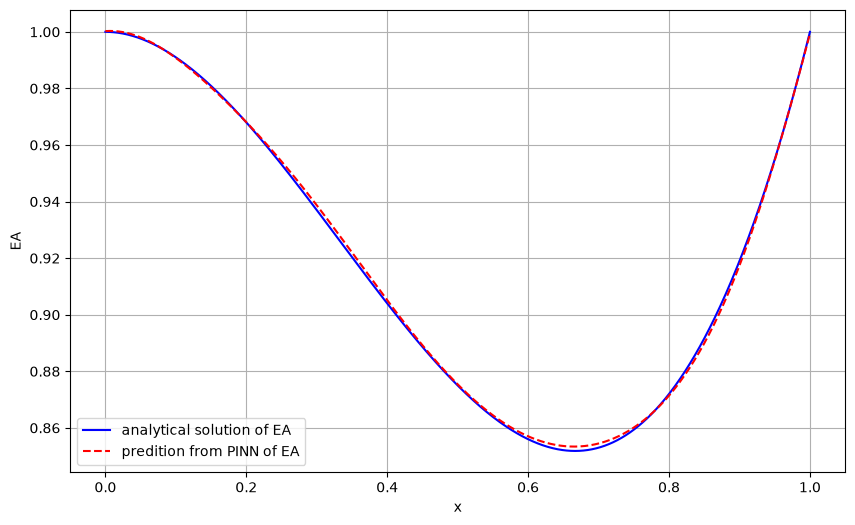

In [90]:
model = PINN_tanh()
trained_pinn, losses = training_model(model)
EA = lambda x: x**3-x**2+1
x_test = np.linspace(0,1,1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype=torch.float32)
u_test_tensor = torch.sin(2*np.pi*x_test_tensor)
EA_pred = trained_pinn(x_test_tensor, u_test_tensor).detach().numpy()

fig, ax = plt.subplots(1,1, figsize=(10,6))
ax.plot(x_test,EA(x_test), 'blue', label='analytical solution of EA')
ax.plot(x_test,EA_pred, 'red', linestyle='--', label='predition from PINN of EA')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('EA')
ax.grid(True)

**e)** Study the influence of noise in the displacement measurements by adding Gaussian noise with a standard deviation of 0.01.

Training 0/5000 epochs, the loss is 3.9745e+02
Training 1000/5000 epochs, the loss is 1.2965e+00
Training 2000/5000 epochs, the loss is 1.1951e-02
Training 3000/5000 epochs, the loss is 4.5337e-03
Training 4000/5000 epochs, the loss is 2.1004e-03


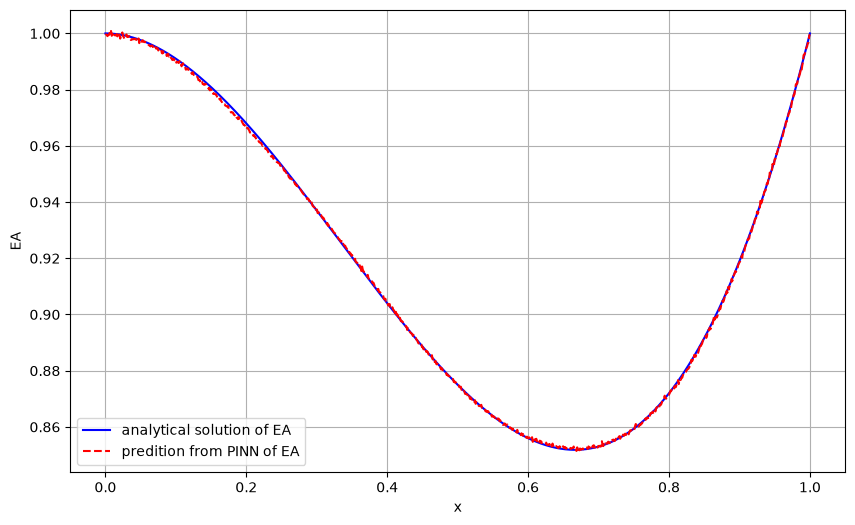

In [91]:
model = PINN_tanh()
trained_pinn, losses = training_model(model)
EA = lambda x: x**3-x**2+1
x_test = np.linspace(0,1,1000)
x_test_tensor = torch.tensor(x_test.reshape(-1,1), dtype=torch.float32)
u_test_tensor = torch.sin(2*np.pi*x_test_tensor) + 0.01 * torch.randn_like(x_test_tensor)
EA_pred = trained_pinn(x_test_tensor, u_test_tensor).detach().numpy()

fig, ax = plt.subplots(1,1, figsize=(10,6))
ax.plot(x_test,EA(x_test), 'blue', label='analytical solution of EA')
ax.plot(x_test,EA_pred, 'red', linestyle='--', label='predition from PINN of EA')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('EA')
ax.grid(True)